# Inference with the DSPy-free fine-tuned model, driven through `dspy.Predict`

`sft_training_llm_nodspy.ipynb` fine-tuned `Qwen/Qwen2.5-7B-Instruct` on a **hand-written**
system prompt + plain JSON input/output (`{"groups": [[...]]}`) -- not DSPy's `ChatAdapter`
bracket markup (`[[ ## groups ## ]]`) or `JSONAdapter`'s auto-generated field-schema wording.

If we plug the resulting checkpoint into DSPy with the stock `ChatAdapter`/`JSONAdapter`, the
model sees a prompt shape it never trained on -- close in spirit, but different wording/framing.
So this notebook defines a minimal custom `dspy.Adapter` subclass, `PlainJSONAdapter`, whose
`format()`/`parse()` reproduce the *exact* training-time system prompt, input JSON, and output
JSON parsing. That keeps the model's actual input distribution identical to training, while the
call site is still ordinary `dspy.Predict(IdentifyGroups)(...)` -- interchangeable with the rest
of this repo's DSPy-driven pipeline (`fetch_groups.py`, `inference_tasks_multi.py`, etc.).

**Requirements**: `py10-dspy` conda kernel, a free GPU to load the merged 7B checkpoint.

In [1]:
import json
import os
import uuid
import datetime

os.environ.setdefault('CUDA_VISIBLE_DEVICES', '1')  # pin to a single free GPU (see nvidia-smi)

import dspy
from vllm import LLM, SamplingParams

from prompts import IdentifyGroups
from sft_data_utils import build_sft_examples

/lp-dev/anaconda3/envs/py10-dspy/lib/python3.10/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
/lp-dev/anaconda3/envs/py10-dspy/lib/python3.10/site-packages/transformers/utils/hub.py:110: FutureWarning: Using `TRANSFORMERS_CACHE` is deprecated and will be removed in v5 of Transformers. Use `HF_HOME` instead.
  warnings.warn(


## In-process vLLM `dspy.LM` wrapper

Same `VLLMOfflineLM` used in `inference.ipynb` -- generic, model-agnostic. It just forwards
whatever `messages` the configured adapter builds straight to vLLM's offline `LLM.chat(...)`, so
it works unchanged with the custom adapter defined below.

In [2]:
class VLLMOfflineLM(dspy.LM):
    """DSPy-compatible LM wrapper around an in-process (offline) vLLM engine."""

    def __init__(self, model, max_tokens=4096, temperature=0.6, **engine_kwargs):
        # Pass a litellm-compatible name to the base class so it doesn't error.
        # We override __call__ so litellm is never actually invoked.
        super().__init__(model=f"openai/{model}", temperature=temperature, max_tokens=max_tokens)

        self.model_name = model
        self.max_tokens = max_tokens
        self.temperature = temperature
        self.engine = LLM(model=model, trust_remote_code=True, **engine_kwargs)

    def __call__(self, prompt=None, messages=None, **kwargs):
        if messages is None:
            messages = [{"role": "user", "content": prompt}]

        sampling_params = SamplingParams(temperature=self.temperature, max_tokens=self.max_tokens)
        [result] = self.engine.chat(messages, sampling_params=sampling_params, use_tqdm=False)
        text = result.outputs[0].text
        outputs = [text]

        entry = {
            "prompt": prompt,
            "messages": messages,
            "kwargs": kwargs,
            "response": text,
            "outputs": outputs,
            "usage": {
                "prompt_tokens": len(result.prompt_token_ids),
                "completion_tokens": len(result.outputs[0].token_ids),
                "total_tokens": len(result.prompt_token_ids) + len(result.outputs[0].token_ids),
            },
            "cost": None,
            "timestamp": datetime.datetime.now().isoformat(),
            "uuid": str(uuid.uuid4()),
            "model": self.model,
            "response_model": self.model_name,
            "model_type": "chat",
        }
        self.update_history(entry)

        return outputs

## Custom adapter matching the training-time prompt/parse exactly

`SYSTEM_PROMPT` below is copied verbatim from `sft_training_llm_nodspy.ipynb`. `format()` builds
exactly the two messages the model was trained on (system + `json.dumps(detections)` user turn,
no few-shot demos, since none were used in training). `parse()` does the inverse of the training
target (`json.dumps({"groups": ...})`) -- `json.loads` the completion and keep only keys that are
real signature output fields (just `groups` here).

As `sft_training_llm_nodspy.ipynb` notes: unlike `ChatAdapter`/`JSONAdapter`, there's no
retry/repair if the model's completion isn't valid JSON -- `parse()` will raise.

In [3]:
SYSTEM_PROMPT = (
    "Given a list of people with their 3D positions, group them into sets where each set "
    "contains people who are close to each other in space. Compute all pairwise distances "
    "between people. Choose a reasonable grouping threshold based on the distribution of "
    "these distances. People belong to the same group if their pairwise distances are below "
    "this threshold. Return only non-empty groups. Do not merge distant people into the same "
    "group. Do not hallucinate non-existent person_id.\n\n"
    "You are given a JSON array of people, each an object with keys 'person_id', 'x', 'y', 'z'.\n"
    "Respond with ONLY a JSON object of the form {\"groups\": [[person_id, ...], ...]} "
    "and no other text. All ids should appear at least once."
)


class PlainJSONAdapter(dspy.Adapter):
    """Reproduces sft_training_llm_nodspy.ipynb's exact prompt/response format."""

    def format(self, signature, demos, inputs):
        return [
            {"role": "system", "content": SYSTEM_PROMPT},
            {"role": "user", "content": json.dumps(inputs["detections"])},
        ]

    def parse(self, signature, completion):
        fields = json.loads(completion)
        return {k: v for k, v in fields.items() if k in signature.output_fields}

## Load the merged fine-tuned checkpoint and configure DSPy

`dspy.Predict(IdentifyGroups)` -- not `dspy.ChainOfThought` -- matches training exactly, since no
`reasoning` field was ever trained.

In [4]:
lm = VLLMOfflineLM(
    model='sft_output/qwen2.5-7b-groups-merged-nodspy',
    max_tokens=512,
    temperature=0.0,
)
dspy.configure(lm=lm, adapter=PlainJSONAdapter())

predict = dspy.Predict(IdentifyGroups)

INFO 07-05 04:26:56 [utils.py:233] non-default args: {'trust_remote_code': True, 'disable_log_stats': True, 'model': 'sft_output/qwen2.5-7b-groups-merged-nodspy'}
INFO 07-05 04:26:56 [model.py:549] Resolved architecture: Qwen2ForCausalLM
INFO 07-05 04:26:56 [model.py:1678] Using max model len 32768
INFO 07-05 04:26:56 [scheduler.py:238] Chunked prefill is enabled with max_num_batched_tokens=8192.
INFO 07-05 04:26:56 [vllm.py:790] Asynchronous scheduling is enabled.


The tokenizer you are loading from 'sft_output/qwen2.5-7b-groups-merged-nodspy' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


(EngineCore pid=1257096) INFO 07-05 04:26:57 [core.py:105] Initializing a V1 LLM engine (v0.19.0) with config: model='sft_output/qwen2.5-7b-groups-merged-nodspy', speculative_config=None, tokenizer='sft_output/qwen2.5-7b-groups-merged-nodspy', skip_tokenizer_init=False, tokenizer_mode=auto, revision=None, tokenizer_revision=None, trust_remote_code=True, dtype=torch.bfloat16, max_seq_len=32768, download_dir=None, load_format=auto, tensor_parallel_size=1, pipeline_parallel_size=1, data_parallel_size=1, decode_context_parallel_size=1, dcp_comm_backend=ag_rs, disable_custom_all_reduce=False, quantization=None, enforce_eager=False, enable_return_routed_experts=False, kv_cache_dtype=auto, device_config=cuda, structured_outputs_config=StructuredOutputsConfig(backend='auto', disable_any_whitespace=False, disable_additional_properties=False, reasoning_parser='', reasoning_parser_plugin='', enable_in_reasoning=False), observability_config=ObservabilityConfig(show_hidden_metrics_for_version=None,

(EngineCore pid=1257096) <frozen importlib._bootstrap_external>:1184: FutureWarning: The cuda.cudart module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.runtime module instead.
(EngineCore pid=1257096) <frozen importlib._bootstrap_external>:1184: FutureWarning: The cuda.nvrtc module is deprecated and will be removed in a future release, please switch to use the cuda.bindings.nvrtc module instead.
Loading safetensors checkpoint shards:   0% Completed | 0/4 [00:00<?, ?it/s]
Loading safetensors checkpoint shards:  25% Completed | 1/4 [00:00<00:00,  3.11it/s]
Loading safetensors checkpoint shards:  50% Completed | 2/4 [00:00<00:00,  2.84it/s]
Loading safetensors checkpoint shards:  75% Completed | 3/4 [00:00<00:00,  3.08it/s]
Loading safetensors checkpoint shards: 100% Completed | 4/4 [00:01<00:00,  3.78it/s]
(EngineCore pid=1257096) 


(EngineCore pid=1257096) INFO 07-05 04:27:01 [default_loader.py:384] Loading weights took 1.07 seconds
(EngineCore pid=1257096) INFO 07-05 04:27:02 [gpu_model_runner.py:4820] Model loading took 14.25 GiB memory and 1.693996 seconds
(EngineCore pid=1257096) INFO 07-05 04:27:05 [backends.py:1051] Using cache directory: /home/nvidia/.cache/vllm/torch_compile_cache/0b6ae8ee0e/rank_0_0/backbone for vLLM's torch.compile
(EngineCore pid=1257096) INFO 07-05 04:27:05 [backends.py:1111] Dynamo bytecode transform time: 2.25 s
(EngineCore pid=1257096) INFO 07-05 04:27:07 [backends.py:285] Directly load the compiled graph(s) for compile range (1, 8192) from the cache, took 1.892 s
(EngineCore pid=1257096) INFO 07-05 04:27:07 [decorators.py:303] Directly load AOT compilation from path /home/nvidia/.cache/vllm/torch_compile_cache/torch_aot_compile/20ce487854c415df712a4bd643c22294dcb477fb626070cd34214b0daa732d41/rank_0_0/model
(EngineCore pid=1257096) INFO 07-05 04:27:07 [monitor.py:48] torch.compile 

Capturing CUDA graphs (mixed prefill-decode, 
Capturing CUDA graphs (decode, FULL): 100%|█|


(EngineCore pid=1257096) INFO 07-05 04:27:16 [gpu_model_runner.py:6046] Graph capturing finished in 4 secs, took 0.47 GiB
(EngineCore pid=1257096) INFO 07-05 04:27:16 [gpu_worker.py:597] CUDA graph pool memory: 0.47 GiB (actual), 0.55 GiB (estimated), difference: 0.07 GiB (15.2%).
(EngineCore pid=1257096) INFO 07-05 04:27:16 [core.py:283] init engine (profile, create kv cache, warmup model) took 13.66 seconds


## Try it on a held-out example

Same held-out scenarios (last 3 of 27, sorted) that `sft_training_llm_nodspy.ipynb` excluded from
training, so this is a genuine out-of-sample check.

In [5]:
examples = build_sft_examples(scenario_range=None, require_image=False)
scenario_ids = sorted({e['scenario_idx'] for e in examples})
val_scenarios = set(scenario_ids[-3:])  # same split as sft_training_llm_nodspy.ipynb
val_examples = [e for e in examples if e['scenario_idx'] in val_scenarios]

holdout = val_examples[0]
prediction = predict(detections=holdout['frame_input_data'])

print('predicted groups:', prediction.groups)
print('ground-truth groups:', holdout['gt_groups'])
print()
print('exact messages sent to the model:')
print(json.dumps(lm.history[-1]['messages'], indent=2))

The tokenizer you are loading from 'sft_output/qwen2.5-7b-groups-merged-nodspy' with an incorrect regex pattern: https://huggingface.co/mistralai/Mistral-Small-3.1-24B-Instruct-2503/discussions/84#69121093e8b480e709447d5e. This will lead to incorrect tokenization. You should set the `fix_mistral_regex=True` flag when loading this tokenizer to fix this issue.


INFO 07-05 04:27:22 [hf.py:314] Detected the chat template content format to be 'string'. You can set `--chat-template-content-format` to override this.
predicted groups: [[11], [45, 68], [41, 40], [18], [24], [208], [287], [1, 9], [39], [282, 281, 234, 233], [5, 6], [95], [94, 93], [236], [235], [26], [170], [168, 166, 167], [72], [67], [25], [65], [47, 46], [60], [52], [28], [56], [66], [59], [175], [55], [192], [196], [98], [42, 43], [193], [238], [197], [44], [97]]
ground-truth groups: [[11], [45], [68], [41], [40], [18], [24, 26], [208, 13, 14], [287], [1], [39], [282], [281], [234], [5], [95], [94], [93], [233], [6], [9, 10], [192], [196, 139], [8, 98, 7], [42], [193], [43, 44], [236], [235], [170], [168], [72], [166], [167], [176, 175], [67, 65, 64], [25], [47, 46], [60, 189], [52], [28], [56], [66], [59], [55], [54, 58], [53], [51], [19, 20], [162], [144], [15], [32], [30], [288], [102, 110], [23, 22], [16], [17], [34], [29], [33], [138], [4, 2], [142], [3], [259], [256], [253]

## Alternative: predict on a real scenario frame and visualize on the image

Same real-scenario-JSON + frame-image setup `inference.ipynb` uses (`get_frame_bboxes`), instead
of a held-out example from `build_sft_examples`. `get_dspy_cot(mode, prompt_method)` is called only
to get the correct `use_direction` flag for this `prompt_method` -- its returned `dspy.ChainOfThought`
module is **not** used below. `PlainJSONAdapter.format()` ignores the signature entirely (it always
sends the exact training-time prompt), so wrapping in `ChainOfThought` wouldn't change what's sent to
the model, but the fine-tuned checkpoint was never trained to produce a `reasoning` field, so we keep
using the plain `predict = dspy.Predict(IdentifyGroups)` defined above instead.

Reuses `utils.save_frame` (the same function `fetch_groups.py`/`inference.ipynb` call) to draw one
color per predicted group on the frame and save/display it.

In [15]:
import matplotlib.pyplot as plt
from PIL import Image

from utils import get_dspy_cot, get_frame_bboxes, save_frame

scenario_path = '../../gold_SEKAI_900_3/jsons_step5/clip_0006.json'
frame_id = 1
frame_path = '../../gold_SEKAI_900_3/videos_frames/clip_0006/00001.jpeg'

with open(scenario_path, 'r') as f:
    data = json.load(f)

print(data['dataset'], '-', len(data['frames']), 'frames')

sekai - 50 frames


In [16]:
mode = 'llm'
prompt_method = 'p1'
depth_method = 'detany_3D'

_, use_direction = get_dspy_cot(mode, prompt_method)  # only used for use_direction (False for p1);
                                                        # the returned ChainOfThought module is unused,
                                                        # see markdown above

frame_input_data, personid2bbox = get_frame_bboxes(data, use_direction, depth_method, frame_id, prompt_method)
print(f'{len(frame_input_data)} people detected in frame {frame_id}')

prediction = predict(detections=frame_input_data)
print('predicted groups:', prediction.groups)

11 people detected in frame 1
predicted groups: [[1, 2, 3, 6], [4], [5], [7], [8], [9], [10], [11]]


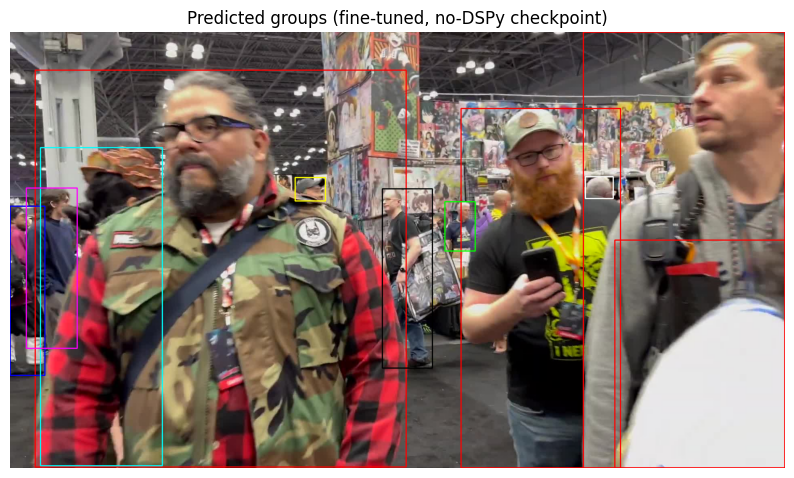

In [17]:
output = {'groups': prediction.groups, 'frame_id': frame_id, 'id_tobbox': personid2bbox}

res_path = 'demo_predictions'
save_filename = 'clip_0004_sft'
model_name = lm.model_name  # 'sft_output/qwen2.5-7b-groups-merged-nodspy'

save_frame(
    output, personid2bbox, res_path, save_filename, frame_path,
    save_image=True, model=model_name, mode=mode,
    depth_method=depth_method, prompt_method=prompt_method, frame_id=frame_id,
)

result_path = os.path.join(
    res_path, model_name.split('/')[1], mode, depth_method,
    prompt_method, str(frame_id), save_filename, 'result.png',
)

plt.figure(figsize=(10, 6))
plt.imshow(Image.open(result_path))
plt.axis('off')
plt.title('Predicted groups (fine-tuned, no-DSPy checkpoint)')
plt.show()

---

**Using this elsewhere in the repo**: `lm` + `PlainJSONAdapter()` is a drop-in replacement for the
usual `dspy.LM(...)` + default adapter in any script that calls `dspy.configure(...)` --
`fetch_groups.py`, `inference_tasks_multi.py`, etc. -- as long as the signature being predicted is
`IdentifyGroups` (single `detections` input, single `groups` output); `PlainJSONAdapter.format()`
would need generalizing (it currently hard-codes the `detections` input field name) to reuse it
with other signatures.

**Serving over HTTP instead of in-process**: swap `VLLMOfflineLM` for a plain
`dspy.LM('openai/sft_output/qwen2.5-7b-groups-merged-nodspy', api_base='http://localhost:8000/v1',
api_key=...)` pointed at `vllm serve sft_output/qwen2.5-7b-groups-merged-nodspy --api-key ...` --
`PlainJSONAdapter` doesn't care which `LM` class it's paired with.